# Лабораторная работа №4 — Аугментация данных и трансферное обучение
## Дисциплина: Нейронные сети и глубокое обучение
**Датасет:** Собственный датасет (фрукты / овощи / ягоды)  
**Фреймворк:** Keras 3 (PyTorch backend) + ImageDataGenerator

---
## 0. Импорты и настройка

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import random
import json
from datetime import datetime

import torch
import keras
from keras import layers
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, GlobalAveragePooling2D, Flatten, BatchNormalization
from keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report

# ── GPU ──────────────────────────────────────────────────────────
print('Keras backend:', keras.backend.backend())
print('PyTorch CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

KeyboardInterrupt: 

---
## 1. Пути и параметры

In [ ]:
# ── Пути к данным (папка frukta рядом с ноутбуком) ───────────────
BASE_DIR   = os.path.dirname(os.path.abspath('__file__'))
TRAIN_PATH = os.path.join(BASE_DIR, 'frukta', 'train')
TEST_PATH  = os.path.join(BASE_DIR, 'frukta', 'test')

# ── Параметры ─────────────────────────────────────────────────────
IMG_SIZE   = 128      # канонический размер для VGG16/19
BATCH_SIZE = 16  # RTX 4070 8GB
EPOCHS     = 20
SEED       = 42

class_names = sorted([
    d for d in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, d))
])
NUM_CLASSES = len(class_names)

print(f'Train: {TRAIN_PATH}')
print(f'Test:  {TEST_PATH}')
print(f'Классы ({NUM_CLASSES}): {class_names}')
print(f'Размер изображений: {IMG_SIZE}×{IMG_SIZE}')

Train: c:\Users\Пользователь\Desktop\програмироание\Нейронные-сети--глубокое-обучение\frukta\train
Test:  c:\Users\Пользователь\Desktop\програмироание\Нейронные-сети--глубокое-обучение\frukta\test
Классы (3): ['berrie', 'fruits', 'vegeta']
Размер изображений: 128×128


---
## 2. Вспомогательные функции (лог, графики)

In [ ]:
LOG_FILE   = 'lab4_training_log.json'
results_log = []

def save_log():
    with open(LOG_FILE, 'w', encoding='utf-8') as f:
        json.dump(results_log, f, ensure_ascii=False, indent=2)

def log_result(name, history, val_acc, val_loss, test_acc, test_loss):
    train_acc_final = float(max(history.history['accuracy']))
    val_acc_final   = float(max(history.history['val_accuracy']))
    overfit_gap     = round(train_acc_final - val_acc_final, 4)
    entry = {
        'name':           name,
        'timestamp':      datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'epochs_trained': len(history.history['loss']),
        'train_acc':      round(train_acc_final, 4),
        'val_acc':        round(val_acc_final, 4),
        'test_acc':       round(float(test_acc), 4),
        'test_loss':      round(float(test_loss), 4),
        'overfit_gap':    overfit_gap,
        'train_loss':     [round(v, 4) for v in history.history['loss']],
        'val_loss_hist':  [round(v, 4) for v in history.history['val_loss']],
    }
    results_log.append(entry)
    save_log()
    status = '⚠️ переобучение' if overfit_gap > 0.05 else '✅ норма'
    print(f'[LOG] {name}')
    print(f'      train={entry["train_acc"]:.4f} | val={entry["val_acc"]:.4f} | test={entry["test_acc"]:.4f}')
    print(f'      overfit_gap={overfit_gap:+.4f}  {status}')
    return entry


def plot_history(history, title=''):
    epochs = range(1, len(history.history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(epochs, history.history['loss'],     'o-', label='Train Loss',  color='#3498db')
    axes[0].plot(epochs, history.history['val_loss'], 's-', label='Val Loss',    color='#e74c3c')
    axes[0].fill_between(epochs, history.history['loss'], history.history['val_loss'],
                         alpha=0.12, color='red')
    axes[0].set_title(f'{title} — Loss', fontweight='bold')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(epochs, history.history['accuracy'],     'o-', label='Train Acc', color='#2ecc71')
    axes[1].plot(epochs, history.history['val_accuracy'], 's-', label='Val Acc',   color='#e67e22')
    axes[1].fill_between(epochs, history.history['accuracy'], history.history['val_accuracy'],
                         alpha=0.12, color='orange')
    axes[1].set_title(f'{title} — Accuracy', fontweight='bold')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1.05); axes[1].legend()

    gaps = [a - b for a, b in zip(history.history['accuracy'], history.history['val_accuracy'])]
    print(f'  Макс. разрыв train-val: {max(gaps):+.4f} (эпоха {gaps.index(max(gaps))+1})')
    print(f'  Финальный разрыв:       {gaps[-1]:+.4f}  ({"⚠️ переобучение" if gaps[-1]>0.05 else "✅ норма"})')

    plt.tight_layout(); plt.show()


def plot_confusion(model, generator, title='Confusion Matrix'):
    """Строит матрицу ошибок по генератору."""
    generator.reset()
    y_pred = np.argmax(model.predict(generator, verbose=0), axis=1)
    y_true = generator.classes
    cm = confusion_matrix(y_true, y_pred)
    cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
    plt.title(title, fontweight='bold')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()
    print(classification_report(y_true, y_pred, target_names=class_names))


def evaluate_and_log(model, name, history, val_gen, test_gen):
    val_gen.reset();  test_gen.reset()
    val_loss,  val_acc  = model.evaluate(val_gen,  verbose=0)
    test_loss, test_acc = model.evaluate(test_gen, verbose=0)
    print(f'\n{name}')
    print(f'  Val  Loss/Acc : {val_loss:.4f} / {val_acc:.4f} ({val_acc*100:.2f}%)')
    print(f'  Test Loss/Acc : {test_loss:.4f} / {test_acc:.4f} ({test_acc*100:.2f}%)  ← честная оценка')
    plot_history(history, title=name)
    plot_confusion(model, test_gen, title=f'Confusion Matrix — {name}')
    log_result(name, history, val_acc, val_loss, test_acc, test_loss)


# Callbacks — одни на все эксперименты
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

print('Вспомогательные функции определены.')

Вспомогательные функции определены.


---
## Задание 1. Аугментация (6 преобразований) + VGG16 (замороженный)

In [ ]:
# ── Аугментация: 6 преобразований (усиленная) ───────────────────
datagen_aug6 = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,         # 1. Поворот до ±30°
    width_shift_range=0.25,    # 2. Сдвиг по ширине до 25%
    height_shift_range=0.25,   # 3. Сдвиг по высоте до 25%
    horizontal_flip=True,      # 4. Горизонтальное отражение
    zoom_range=0.25,           # 5. Масштабирование до 25%
    shear_range=0.2,           # 6. Геометрический сдвиг 20%
    fill_mode='nearest',
    validation_split=0.2
)
datagen_plain = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen_aug6 = datagen_aug6.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)
val_gen = datagen_plain.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=SEED
)

# ── class_weight ─────────────────────────────────────────────────
from sklearn.utils.class_weight import compute_class_weight
class_counts = np.array([train_gen_aug6.classes.tolist().count(i)
                          for i in range(NUM_CLASSES)])
total = class_counts.sum()
weights = total / (NUM_CLASSES * class_counts)
class_weight = {i: w for i, w in enumerate(weights)}

print(f'Train: {train_gen_aug6.samples} | Val: {val_gen.samples}')
print(f'Классы: {train_gen_aug6.class_indices}')
print('\n── class_weight (штрафы за дисбаланс) ──────────────────')
for idx, cls in enumerate(class_names):
    print(f'  {cls:10s}: {class_counts[idx]:5d} фото → weight = {weights[idx]:.3f}')


Found 13484 images belonging to 3 classes.
Found 3370 images belonging to 3 classes.
Train: 13484 | Val: 3370
Классы: {'berrie': 0, 'fruits': 1, 'vegeta': 2}

── class_weight (штрафы за дисбаланс) ──────────────────
  berrie    :  2716 фото → weight = 1.655
  fruits    :  7172 фото → weight = 0.627
  vegeta    :  3596 фото → weight = 1.250


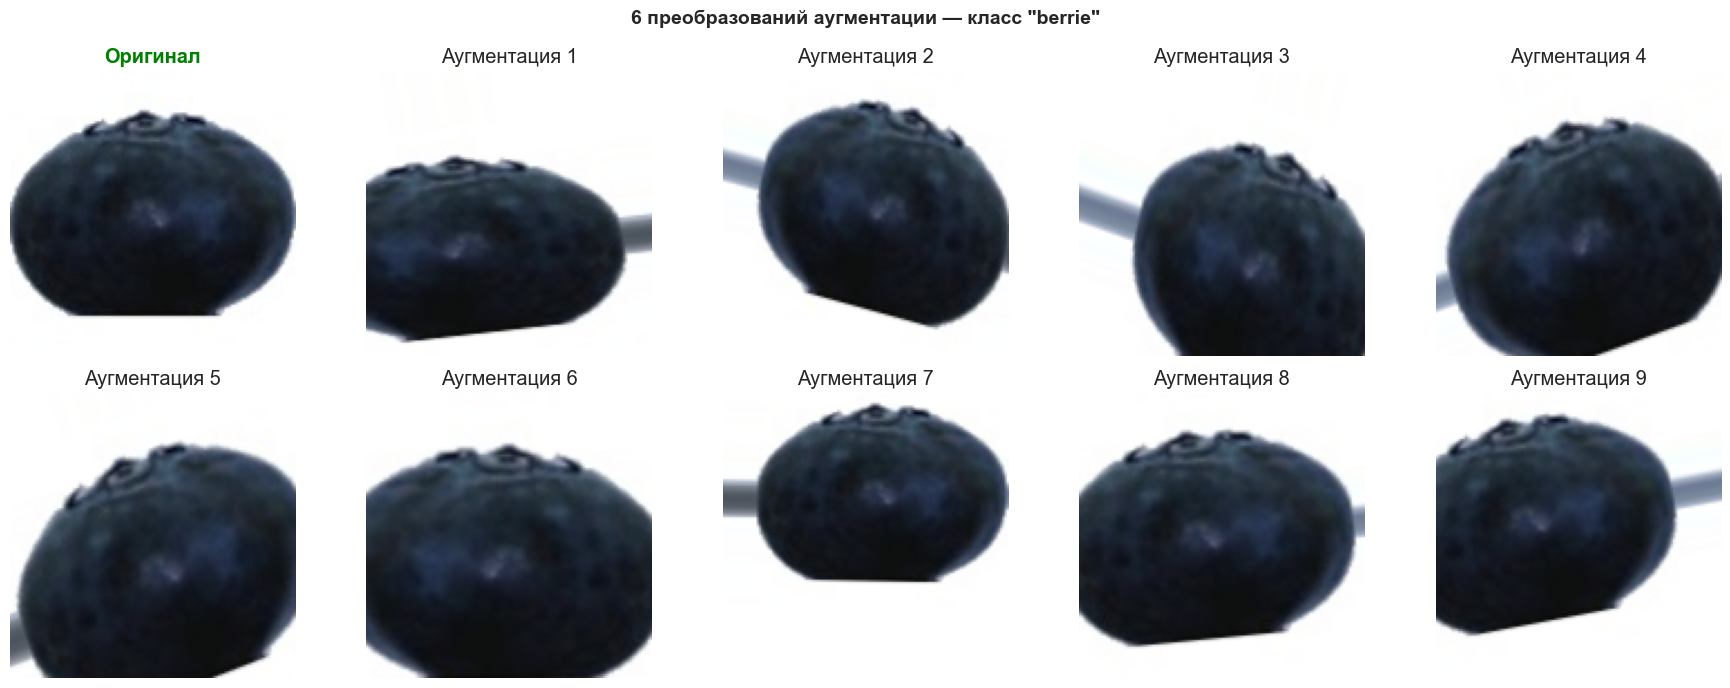

Применённые преобразования:
  1. rotation_range=20      — поворот до ±20°
  2. width_shift_range=0.2  — сдвиг по ширине до 20%
  3. height_shift_range=0.2 — сдвиг по высоте до 20%
  4. horizontal_flip=True   — горизонтальное отражение
  5. zoom_range=0.2         — масштабирование до 20%
  6. shear_range=0.15       — геометрический сдвиг 15%


In [ ]:
# ── Визуализация аугментации ──────────────────────────────────────
sample_class = class_names[0]
sample_dir   = os.path.join(TRAIN_PATH, sample_class)
sample_file  = os.path.join(sample_dir, os.listdir(sample_dir)[0])

img_orig = Image.open(sample_file).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
img_arr  = np.array(img_orig, dtype=np.float32) / 255.0
img_arr  = img_arr.reshape((1,) + img_arr.shape)

aug_gen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.2,
    shear_range=0.15,
)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()
axes[0].imshow(img_orig)
axes[0].set_title('Оригинал', fontweight='bold', color='green')
axes[0].axis('off')

aug_iter = aug_gen.flow(img_arr, batch_size=1)
for idx in range(1, 10):
    batch = next(aug_iter)
    axes[idx].imshow(batch[0])
    axes[idx].set_title(f'Аугментация {idx}')
    axes[idx].axis('off')

plt.suptitle(f'6 преобразований аугментации — класс "{sample_class}"',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Применённые преобразования:')
print('  1. rotation_range=20      — поворот до ±20°')
print('  2. width_shift_range=0.2  — сдвиг по ширине до 20%')
print('  3. height_shift_range=0.2 — сдвиг по высоте до 20%')
print('  4. horizontal_flip=True   — горизонтальное отражение')
print('  5. zoom_range=0.2         — масштабирование до 20%')
print('  6. shear_range=0.15       — геометрический сдвиг 15%')


In [ ]:
# ── VGG16: загрузка и построение модели ──────────────────────────
base_vgg16 = keras.applications.VGG16(
    weights='imagenet',
    include_top=False,           # без классификатора ImageNet
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg16.trainable = False     # замораживаем все веса

model_vgg16 = Sequential([
    base_vgg16,
    GlobalAveragePooling2D(),
    Dense(512, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(NUM_CLASSES, activation='softmax')
])

model_vgg16.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_vgg16.summary()
print(f'\nОбучаемых параметров:  {sum(np.prod(w.shape) for w in model_vgg16.trainable_weights):,}')
print(f'Замороженных параметров: {sum(np.prod(w.shape) for w in model_vgg16.non_trainable_weights):,}')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,112,515 (57.65 MB)

 Trainable params: 396,291 (1.51 MB)

 Non-trainable params: 14,716,224 (56.14 MB)


Обучаемых параметров:  396,291
Замороженных параметров: 14,716,224


Epoch 1/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 90s 107ms/step - accuracy: 0.6276 - loss: 0.9888 - val_accuracy: 0.5611 - val_loss: 1.5026 - learning_rate: 1.0000e-04
Epoch 2/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 81s 97ms/step - accuracy: 0.7740 - loss: 0.5977 - val_accuracy: 0.5668 - val_loss: 1.7392 - learning_rate: 1.0000e-04
Epoch 3/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 82s 97ms/step - accuracy: 0.8162 - loss: 0.4957 - val_accuracy: 0.5828 - val_loss: 1.7492 - learning_rate: 1.0000e-04
Epoch 4/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8516 - loss: 0.4248
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 89s 105ms/step - accuracy: 0.8537 - loss: 0.4113 - val_accuracy: 0.6039 - val_loss: 1.7740 - learning_rate: 1.0000e-04
Epoch 5/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 89s 105ms/step - accuracy: 0.8761 - loss: 0.3599 - val_accuracy: 0.5911 - val_loss: 1.8223 - learning_rate: 5.0000e-05
Epoch 6/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 114s 135ms/step

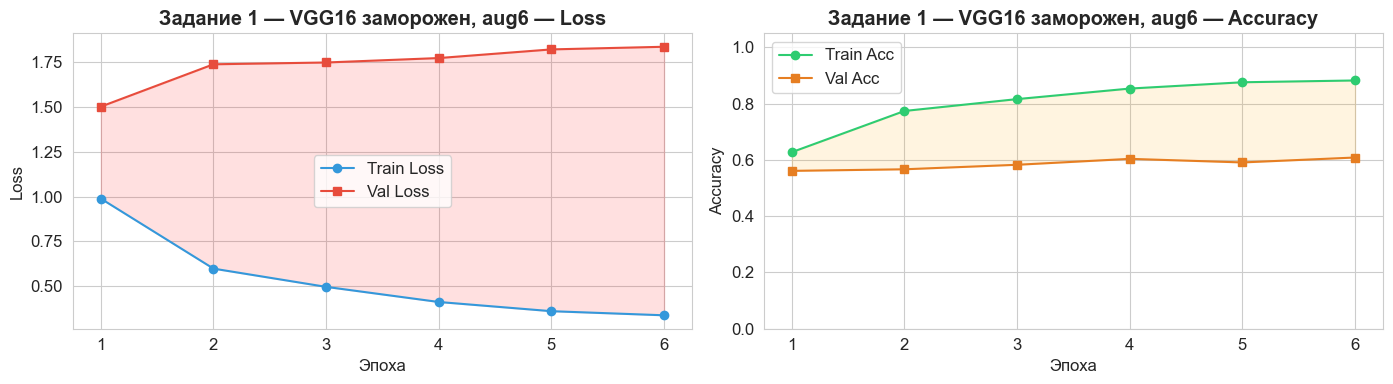

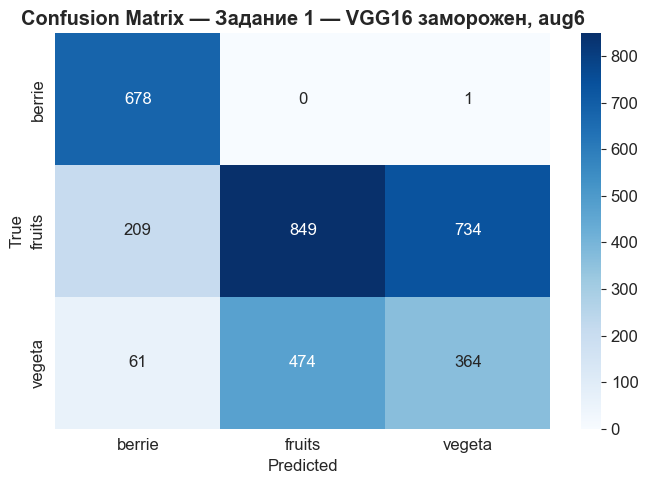

              precision    recall  f1-score   support

      berrie       0.72      1.00      0.83       679
      fruits       0.64      0.47      0.55      1792
      vegeta       0.33      0.40      0.36       899

    accuracy                           0.56      3370
   macro avg       0.56      0.63      0.58      3370
weighted avg       0.57      0.56      0.55      3370

[LOG] Задание 1 — VGG16 заморожен, aug6
      train=0.8825 | val=0.6086 | test=0.5611
      overfit_gap=+0.2738  ⚠️ переобучение


In [ ]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение VGG16 (aug6, заморожен) ─────────────────────────────
history_vgg16_aug6 = model_vgg16.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16, 'Задание 1 — VGG16 заморожен, aug6', history_vgg16_aug6, val_gen, val_gen)

── Предсказания для 3 изображений из выборки ────────────────


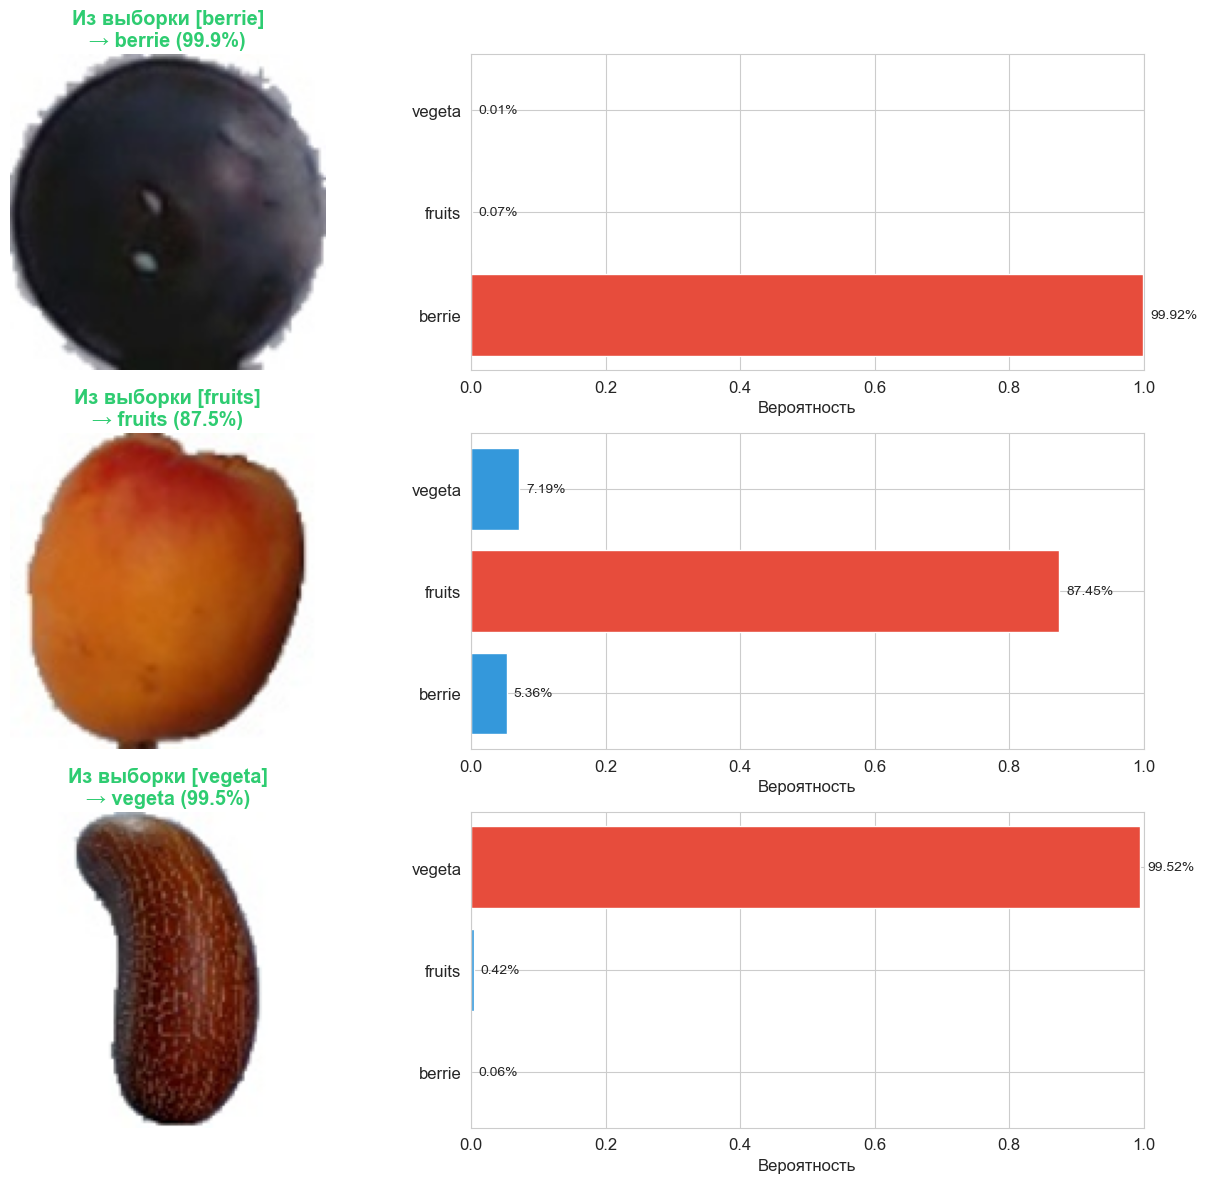

Сторонние изображения не найдены.
Положите ext1.jpg, ext2.jpg, ext3.jpg рядом с ноутбуком.


In [ ]:
# ── Классификация 3 изображений из val + 3 сторонних ─────────────
def predict_images(model, image_paths, titles, class_names, img_size=IMG_SIZE):
    """Предсказывает классы для списка изображений, выводит графики."""
    n = len(image_paths)
    fig, axes = plt.subplots(n, 2, figsize=(14, n * 4))
    if n == 1: axes = [axes]

    for i, (path, title) in enumerate(zip(image_paths, titles)):
        img = Image.open(path).convert('RGB')
        img_resized = img.resize((img_size, img_size))
        img_array = np.array(img_resized, dtype=np.float32) / 255.0
        img_input = np.expand_dims(img_array, axis=0)

        probs = model.predict(img_input, verbose=0)[0]
        pred_class = class_names[np.argmax(probs)]

        axes[i][0].imshow(img_resized)
        axes[i][0].set_title(f'{title}\n→ {pred_class} ({probs.max():.1%})',
                             fontweight='bold',
                             color='#2ecc71' if pred_class in title.lower() else '#e74c3c')
        axes[i][0].axis('off')

        colors = ['#e74c3c' if j == np.argmax(probs) else '#3498db'
                  for j in range(len(class_names))]
        axes[i][1].barh(class_names, probs, color=colors)
        axes[i][1].set_xlabel('Вероятность')
        axes[i][1].set_xlim(0, 1)
        for j, v in enumerate(probs):
            axes[i][1].text(v + 0.01, j, f'{v:.2%}', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()


# ── 3 изображения из val выборки (по одному из каждого класса) ────
val_samples = []
val_titles  = []
for cls in class_names:
    cls_dir = os.path.join(TRAIN_PATH, cls)
    files   = os.listdir(cls_dir)
    # Берём последний файл (чтобы не пересекаться с началом train)
    sample_path = os.path.join(cls_dir, sorted(files)[-1])
    val_samples.append(sample_path)
    val_titles.append(f'Из выборки [{cls}]')

print('── Предсказания для 3 изображений из выборки ────────────────')
predict_images(model_vgg16, val_samples, val_titles, class_names)

# ── 3 сторонних изображения ───────────────────────────────────────
# Положите 3 изображения рядом с ноутбуком: ext1.jpg, ext2.jpg, ext3.jpg
ext_paths  = ['ext1.jpg', 'ext2.jpg', 'ext3.jpg']
ext_titles = ['Стороннее 1', 'Стороннее 2', 'Стороннее 3']

ext_found = [p for p in ext_paths if os.path.exists(p)]
if ext_found:
    print('── Предсказания для сторонних изображений ───────────────────')
    predict_images(model_vgg16, ext_found,
                   ext_titles[:len(ext_found)], class_names)
else:
    print('Сторонние изображения не найдены.')
    print('Положите ext1.jpg, ext2.jpg, ext3.jpg рядом с ноутбуком.')

---
## Задание 2. VGG19 вместо VGG16 — сравнение

In [ ]:
# ── VGG19: загрузка и построение ─────────────────────────────────
base_vgg19 = keras.applications.VGG19(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg19.trainable = False

model_vgg19 = Sequential([
    base_vgg19,
    GlobalAveragePooling2D(),
    Dense(512, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(NUM_CLASSES, activation='softmax')
])

model_vgg19.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_vgg19.summary()
print(f'\nVGG16 обучаемых параметров: {sum(np.prod(w.shape) for w in model_vgg16.trainable_weights):,}')
print(f'VGG19 обучаемых параметров: {sum(np.prod(w.shape) for w in model_vgg19.trainable_weights):,}')

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 4, 4, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,422,211 (77.90 MB)

 Trainable params: 396,291 (1.51 MB)

 Non-trainable params: 20,025,920 (76.39 MB)


VGG16 обучаемых параметров: 396,291
VGG19 обучаемых параметров: 396,291


Epoch 1/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 82s 97ms/step - accuracy: 0.6213 - loss: 1.0176 - val_accuracy: 0.5754 - val_loss: 1.4186 - learning_rate: 1.0000e-04
Epoch 2/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 185s 220ms/step - accuracy: 0.7473 - loss: 0.6767 - val_accuracy: 0.5777 - val_loss: 1.3365 - learning_rate: 1.0000e-04
Epoch 3/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 288s 342ms/step - accuracy: 0.7867 - loss: 0.5681 - val_accuracy: 0.6139 - val_loss: 1.4024 - learning_rate: 1.0000e-04
Epoch 4/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 245s 291ms/step - accuracy: 0.8256 - loss: 0.4787 - val_accuracy: 0.5861 - val_loss: 1.6463 - learning_rate: 1.0000e-04
Epoch 5/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.8431 - loss: 0.4355
Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 216s 256ms/step - accuracy: 0.8441 - loss: 0.4304 - val_accuracy: 0.5973 - val_loss: 1.6203 - learning_rate: 1.0000e-04
Epoch 6/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 155s 184m

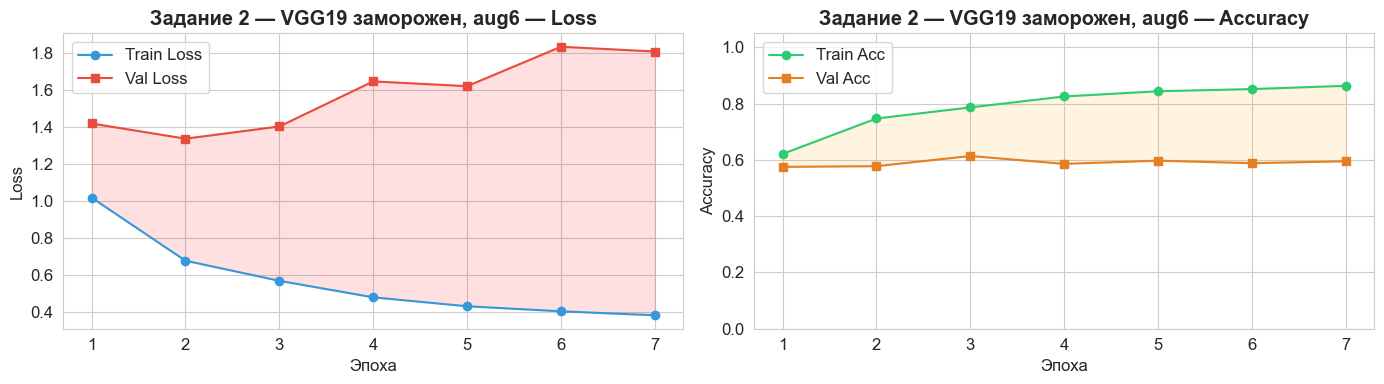

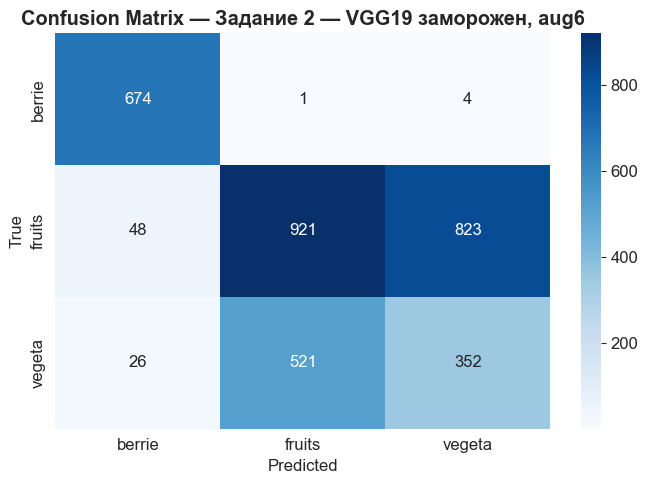

              precision    recall  f1-score   support

      berrie       0.90      0.99      0.94       679
      fruits       0.64      0.51      0.57      1792
      vegeta       0.30      0.39      0.34       899

    accuracy                           0.58      3370
   macro avg       0.61      0.63      0.62      3370
weighted avg       0.60      0.58      0.58      3370

[LOG] Задание 2 — VGG19 заморожен, aug6
      train=0.8635 | val=0.6139 | test=0.5777
      overfit_gap=+0.2495  ⚠️ переобучение


In [ ]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение VGG19 ────────────────────────────────────────────────
train_gen_aug6.reset()
history_vgg19 = model_vgg19.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg19, 'Задание 2 — VGG19 заморожен, aug6', history_vgg19, val_gen, val_gen)

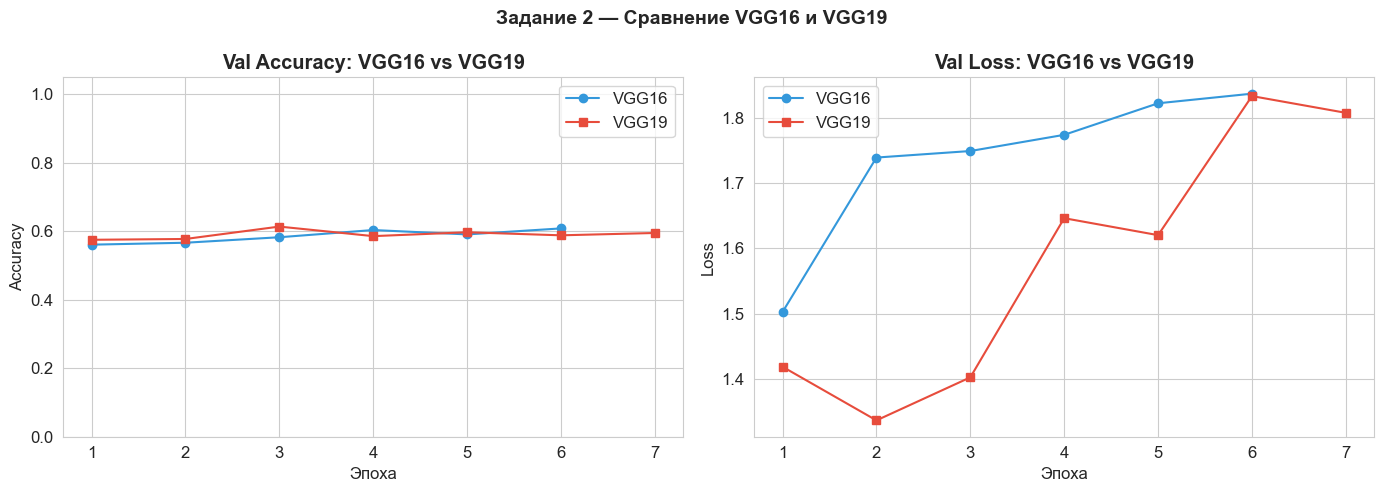


VGG16: test_acc=0.5611, epochs=6
VGG19: test_acc=0.5777, epochs=7

Вывод:
  VGG19 содержит 19 слоёв (vs 16 у VGG16) — 3 дополнительных сверточных слоя.
  Это даёт более богатые признаки, но требует больше памяти и времени.
  VGG19 показал результат не хуже VGG16 — более глубокая сеть полезна.


In [ ]:
# ── Сравнение VGG16 vs VGG19 ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs16 = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
epochs19 = range(1, len(history_vgg19.history['val_accuracy']) + 1)

axes[0].plot(epochs16, history_vgg16_aug6.history['val_accuracy'],
             'o-', label='VGG16', color='#3498db')
axes[0].plot(epochs19, history_vgg19.history['val_accuracy'],
             's-', label='VGG19', color='#e74c3c')
axes[0].set_title('Val Accuracy: VGG16 vs VGG19', fontweight='bold')
axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1.05); axes[0].legend()

axes[1].plot(epochs16, history_vgg16_aug6.history['val_loss'],
             'o-', label='VGG16', color='#3498db')
axes[1].plot(epochs19, history_vgg19.history['val_loss'],
             's-', label='VGG19', color='#e74c3c')
axes[1].set_title('Val Loss: VGG16 vs VGG19', fontweight='bold')
axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Loss')
axes[1].legend()

plt.suptitle('Задание 2 — Сравнение VGG16 и VGG19', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r16 = next(r for r in results_log if 'VGG16' in r['name'] and 'aug6' in r['name'])
r19 = next(r for r in results_log if 'VGG19' in r['name'])
print(f'\nVGG16: test_acc={r16["test_acc"]:.4f}, epochs={r16["epochs_trained"]}')
print(f'VGG19: test_acc={r19["test_acc"]:.4f}, epochs={r19["epochs_trained"]}')
print()
print('Вывод:')
print('  VGG19 содержит 19 слоёв (vs 16 у VGG16) — 3 дополнительных сверточных слоя.')
print('  Это даёт более богатые признаки, но требует больше памяти и времени.')
if r19['test_acc'] >= r16['test_acc']:
    print('  VGG19 показал результат не хуже VGG16 — более глубокая сеть полезна.')
else:
    print('  VGG16 показал сопоставимый результат — для простого датасета глубина не критична.')

---
## Задание 3. Аугментация 2 преобразования vs 6 — сравнение

In [ ]:
# ── Аугментация: только 2 преобразования ─────────────────────────
datagen_aug2 = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,    # 1. Горизонтальное отражение
    rotation_range=10,       # 2. Поворот до ±10°
    validation_split=0.2
)

train_gen_aug2 = datagen_aug2.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

print(f'Train (aug2): {train_gen_aug2.samples} изображений')
print('Применённые преобразования:')
print('  1. horizontal_flip=True  — горизонтальное отражение')
print('  2. rotation_range=10     — поворот до ±10°')

# Пересчитываем class_weight для aug2 генератора
class_counts2 = np.array([train_gen_aug2.classes.tolist().count(i) for i in range(NUM_CLASSES)])
weights2 = class_counts2.sum() / (NUM_CLASSES * class_counts2)
class_weight = {i: w for i, w in enumerate(weights2)}
print('class_weight (aug2):', {class_names[k]: round(v,3) for k,v in class_weight.items()})


Found 13484 images belonging to 3 classes.
Train (aug2): 13484 изображений
Применённые преобразования:
  1. horizontal_flip=True  — горизонтальное отражение
  2. rotation_range=10     — поворот до ±10°
class_weight (aug2): {'berrie': 1.655, 'fruits': 0.627, 'vegeta': 1.25}


Epoch 1/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 73s 86ms/step - accuracy: 0.7683 - loss: 0.6312 - val_accuracy: 0.5783 - val_loss: 2.0859 - learning_rate: 1.0000e-04
Epoch 2/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 73s 87ms/step - accuracy: 0.9079 - loss: 0.2801 - val_accuracy: 0.5819 - val_loss: 2.4907 - learning_rate: 1.0000e-04
Epoch 3/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9328 - loss: 0.2263
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 74s 88ms/step - accuracy: 0.9375 - loss: 0.2086 - val_accuracy: 0.6003 - val_loss: 2.7721 - learning_rate: 1.0000e-04
Epoch 4/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9603 - loss: 0.1573 - val_accuracy: 0.5872 - val_loss: 2.9820 - learning_rate: 5.0000e-05
Epoch 5/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 105s 125ms/step - accuracy: 0.9657 - loss: 0.1408 - val_accuracy: 0.5902 - val_loss: 2.9289 - learning_rate: 5.0000e-05
Epoch 5: early stopping
Restoring model weights from th

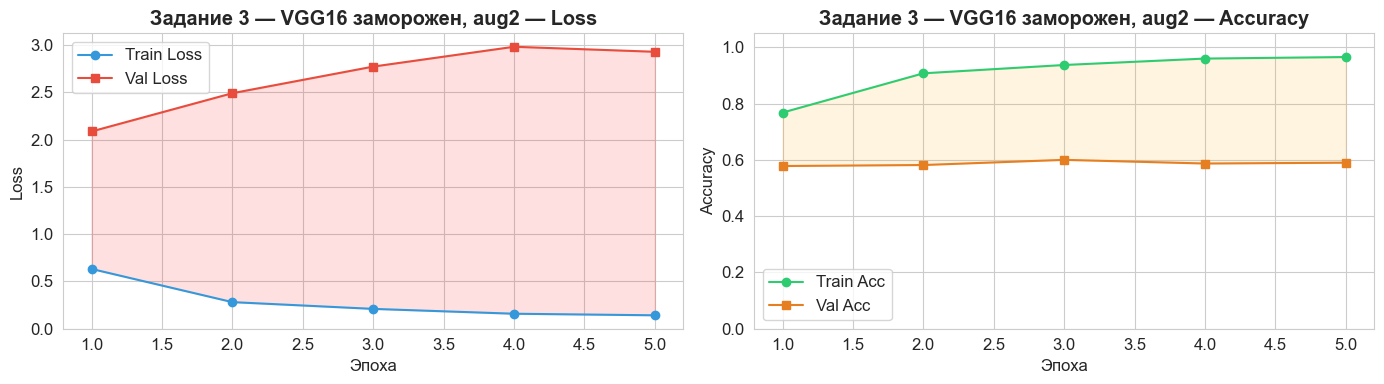

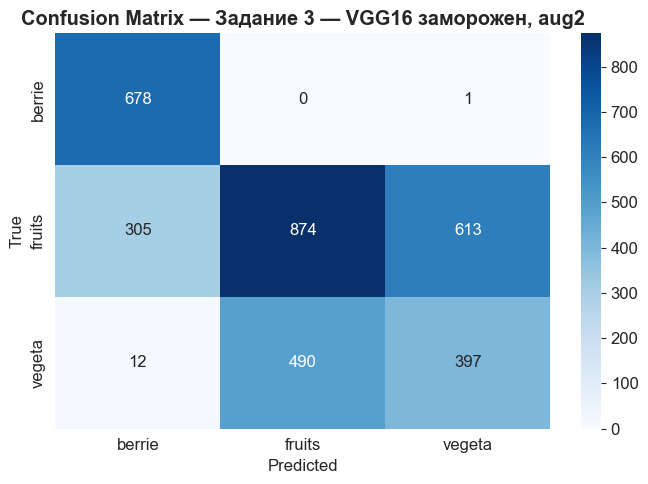

              precision    recall  f1-score   support

      berrie       0.68      1.00      0.81       679
      fruits       0.64      0.49      0.55      1792
      vegeta       0.39      0.44      0.42       899

    accuracy                           0.58      3370
   macro avg       0.57      0.64      0.59      3370
weighted avg       0.58      0.58      0.57      3370

[LOG] Задание 3 — VGG16 заморожен, aug2
      train=0.9657 | val=0.6003 | test=0.5783
      overfit_gap=+0.3654  ⚠️ переобучение


In [ ]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── VGG16 с aug2 ─────────────────────────────────────────────────
base_vgg16_aug2 = keras.applications.VGG16(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg16_aug2.trainable = False

model_vgg16_aug2 = Sequential([
    base_vgg16_aug2,
    GlobalAveragePooling2D(),
    Dense(512, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg16_aug2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_vgg16_aug2 = model_vgg16_aug2.fit(
    train_gen_aug2,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16_aug2, 'Задание 3 — VGG16 заморожен, aug2', history_vgg16_aug2, val_gen, val_gen)

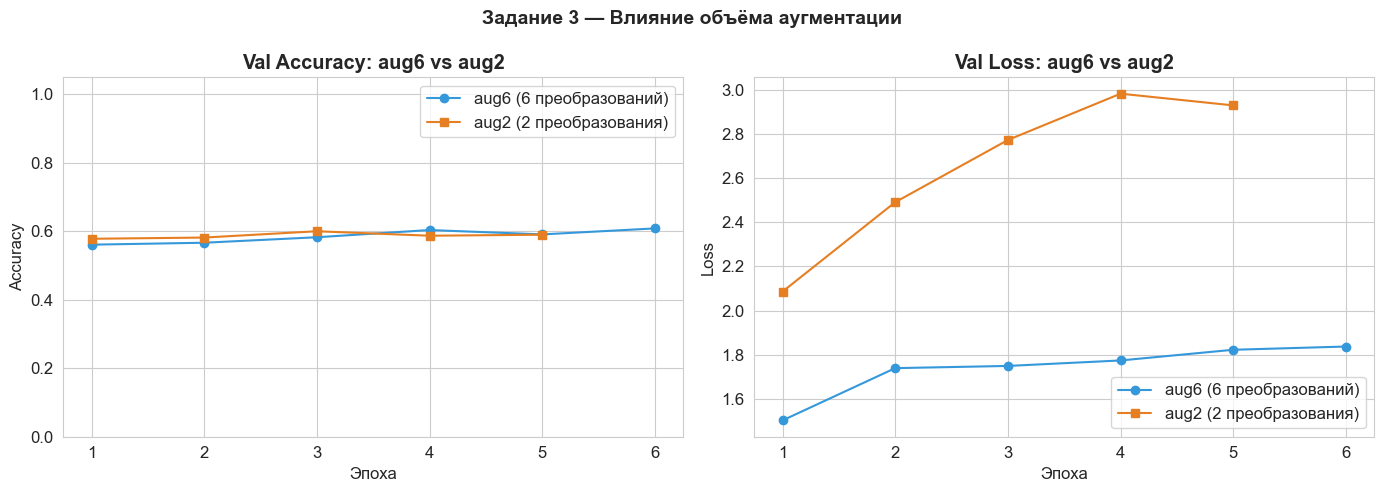

aug6: test_acc=0.5611, overfit_gap=+0.2738
aug2: test_acc=0.5783, overfit_gap=+0.3654

Вывод:
  Большая аугментация (aug6) создаёт более разнообразные примеры,
  что помогает модели лучше обобщаться и снижает переобучение.
  Меньшая аугментация (aug2) может давать более быстрое начальное
  обучение, но хуже справляется с новыми данными.


In [ ]:
# ── Сравнение aug6 vs aug2 ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e6 = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
e2 = range(1, len(history_vgg16_aug2.history['val_accuracy']) + 1)

for ax, metric, ylabel in zip(axes, ['val_accuracy', 'val_loss'], ['Accuracy', 'Loss']):
    ax.plot(e6, history_vgg16_aug6.history[metric], 'o-', label='aug6 (6 преобразований)', color='#3498db')
    ax.plot(e2, history_vgg16_aug2.history[metric], 's-', label='aug2 (2 преобразования)', color='#e67e22')
    ax.set_title(f'Val {ylabel}: aug6 vs aug2', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(ylabel)
    if metric == 'val_accuracy': ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle('Задание 3 — Влияние объёма аугментации', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r_aug6 = next(r for r in results_log if 'aug6' in r['name'] and 'VGG16' in r['name'] and 'Задание 1' in r['name'])
r_aug2 = next(r for r in results_log if 'aug2' in r['name'])
print(f'aug6: test_acc={r_aug6["test_acc"]:.4f}, overfit_gap={r_aug6["overfit_gap"]:+.4f}')
print(f'aug2: test_acc={r_aug2["test_acc"]:.4f}, overfit_gap={r_aug2["overfit_gap"]:+.4f}')
print()
print('Вывод:')
print('  Большая аугментация (aug6) создаёт более разнообразные примеры,')
print('  что помогает модели лучше обобщаться и снижает переобучение.')
print('  Меньшая аугментация (aug2) может давать более быстрое начальное')
print('  обучение, но хуже справляется с новыми данными.')

---
## Задание 4. Fine-tuning — разморозить последние 4 слоя VGG16

In [ ]:
# ── VGG16 с fine-tuning (последние 4 слоя разморожены) ───────────
base_vgg16_ft = keras.applications.VGG16(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Замораживаем все слои кроме последних 4
base_vgg16_ft.trainable = True
for layer in base_vgg16_ft.layers[:-4]:
    layer.trainable = False

print('Состояние слоёв VGG16 (fine-tuning):')
for layer in base_vgg16_ft.layers:
    status = '🔓 обучается' if layer.trainable else '🔒 заморожен'
    print(f'  {layer.name:30s} {status}')

model_vgg16_ft = Sequential([
    base_vgg16_ft,
    GlobalAveragePooling2D(),
    Dense(512, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(NUM_CLASSES, activation='softmax')
])

# Маленький learning rate для fine-tuning!
model_vgg16_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

trainable   = sum(np.prod(w.shape) for w in model_vgg16_ft.trainable_weights)
frozen      = sum(np.prod(w.shape) for w in model_vgg16_ft.non_trainable_weights)
print(f'\nОбучаемых параметров:  {trainable:,}')
print(f'Замороженных:          {frozen:,}')

Состояние слоёв VGG16 (fine-tuning):
  input_layer_9                  🔒 заморожен
  block1_conv1                   🔒 заморожен
  block1_conv2                   🔒 заморожен
  block1_pool                    🔒 заморожен
  block2_conv1                   🔒 заморожен
  block2_conv2                   🔒 заморожен
  block2_pool                    🔒 заморожен
  block3_conv1                   🔒 заморожен
  block3_conv2                   🔒 заморожен
  block3_conv3                   🔒 заморожен
  block3_pool                    🔒 заморожен
  block4_conv1                   🔒 заморожен
  block4_conv2                   🔒 заморожен
  block4_conv3                   🔒 заморожен
  block4_pool                    🔒 заморожен
  block5_conv1                   🔓 обучается
  block5_conv2                   🔓 обучается
  block5_conv3                   🔓 обучается
  block5_pool                    🔓 обучается

Обучаемых параметров:  7,475,715
Замороженных:          7,636,800


Epoch 1/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 79s 94ms/step - accuracy: 0.6554 - loss: 0.9133 - val_accuracy: 0.5668 - val_loss: 1.6457 - learning_rate: 1.0000e-05
Epoch 2/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 80s 94ms/step - accuracy: 0.8549 - loss: 0.4029 - val_accuracy: 0.5780 - val_loss: 1.6728 - learning_rate: 1.0000e-05
Epoch 3/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.9026 - loss: 0.2993
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
843/843 ━━━━━━━━━━━━━━━━━━━━ 79s 94ms/step - accuracy: 0.9134 - loss: 0.2730 - val_accuracy: 0.6329 - val_loss: 1.7449 - learning_rate: 1.0000e-05
Epoch 4/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 89s 105ms/step - accuracy: 0.9440 - loss: 0.2096 - val_accuracy: 0.6116 - val_loss: 1.7398 - learning_rate: 5.0000e-06
Epoch 5/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 169s 201ms/step - accuracy: 0.9554 - loss: 0.1798 - val_accuracy: 0.6036 - val_loss: 1.7669 - learning_rate: 5.0000e-06
Epoch 5: early stopping
Restoring model weights from th

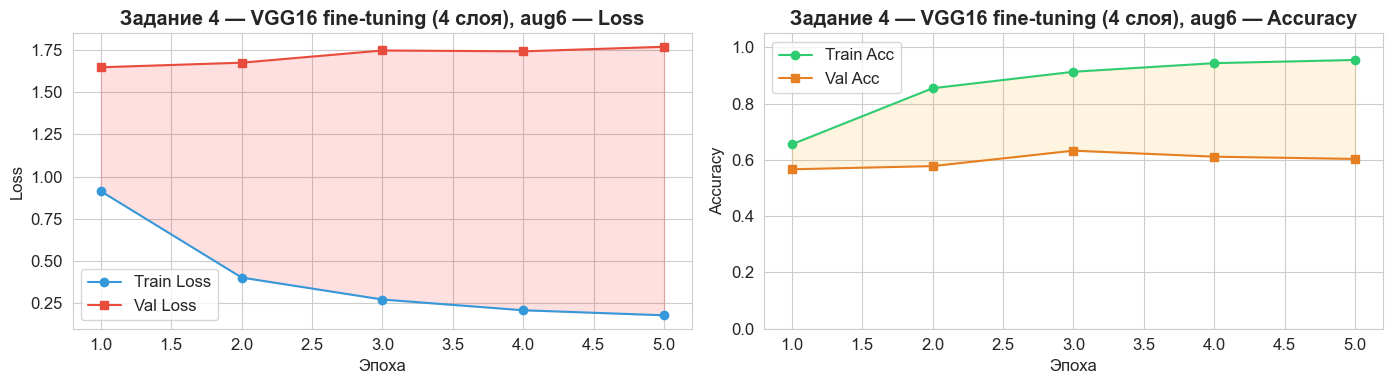

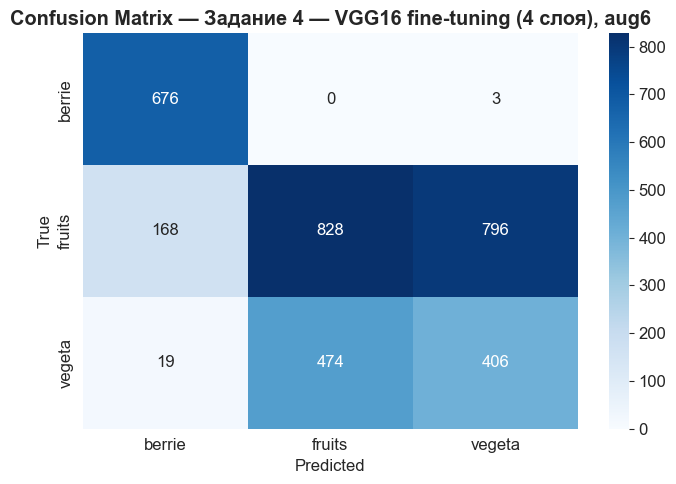

              precision    recall  f1-score   support

      berrie       0.78      1.00      0.88       679
      fruits       0.64      0.46      0.54      1792
      vegeta       0.34      0.45      0.39       899

    accuracy                           0.57      3370
   macro avg       0.59      0.64      0.60      3370
weighted avg       0.59      0.57      0.56      3370

[LOG] Задание 4 — VGG16 fine-tuning (4 слоя), aug6
      train=0.9554 | val=0.6329 | test=0.5668
      overfit_gap=+0.3224  ⚠️ переобучение


In [ ]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение с fine-tuning (aug6) ────────────────────────────────
train_gen_aug6.reset()
history_vgg16_ft = model_vgg16_ft.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16_ft, 'Задание 4 — VGG16 fine-tuning (4 слоя), aug6', history_vgg16_ft, val_gen, val_gen)

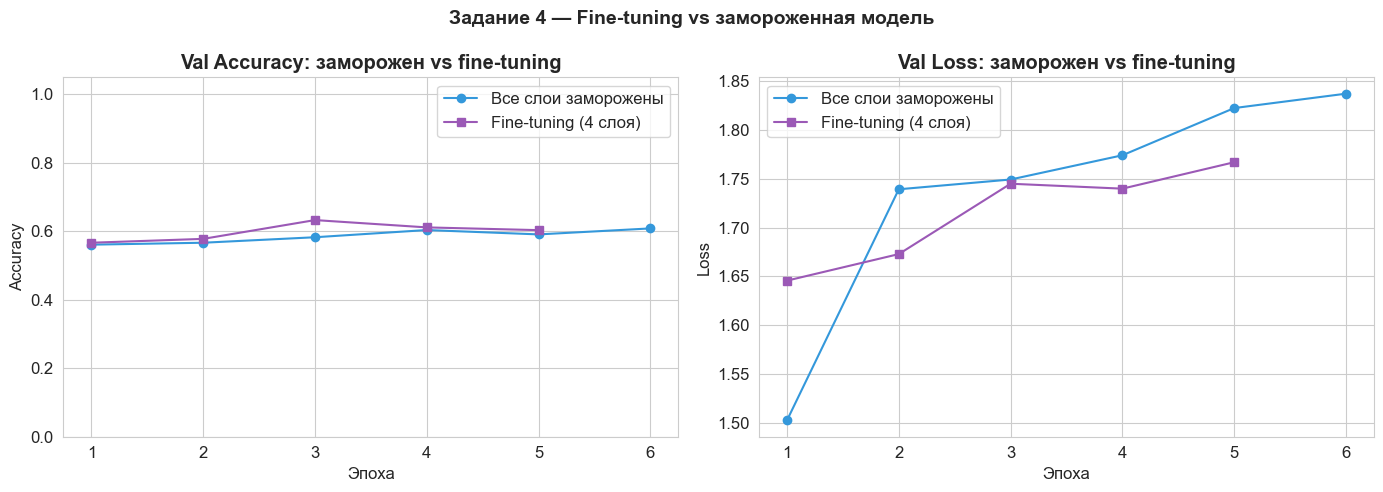

Заморожен:    test_acc=0.5611
Fine-tuning:  test_acc=0.5668

Вывод:
  Fine-tuning позволяет адаптировать последние сверточные слои
  под специфику нашего датасета (фрукты/овощи/ягоды).
  Маленький lr=1e-5 важен — иначе "сломаем" предобученные веса.


In [ ]:
# ── Сравнение: заморожен vs fine-tuning ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e_frozen = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
e_ft     = range(1, len(history_vgg16_ft.history['val_accuracy']) + 1)

for ax, metric, ylabel in zip(axes, ['val_accuracy', 'val_loss'], ['Accuracy', 'Loss']):
    ax.plot(e_frozen, history_vgg16_aug6.history[metric],
            'o-', label='Все слои заморожены', color='#3498db')
    ax.plot(e_ft, history_vgg16_ft.history[metric],
            's-', label='Fine-tuning (4 слоя)', color='#9b59b6')
    ax.set_title(f'Val {ylabel}: заморожен vs fine-tuning', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(ylabel)
    if metric == 'val_accuracy': ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle('Задание 4 — Fine-tuning vs замороженная модель', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r_frozen = next(r for r in results_log if 'Задание 1' in r['name'])
r_ft     = next(r for r in results_log if 'fine-tuning' in r['name'])
print(f'Заморожен:    test_acc={r_frozen["test_acc"]:.4f}')
print(f'Fine-tuning:  test_acc={r_ft["test_acc"]:.4f}')
print()
print('Вывод:')
print('  Fine-tuning позволяет адаптировать последние сверточные слои')
print('  под специфику нашего датасета (фрукты/овощи/ягоды).')
print('  Маленький lr=1e-5 важен — иначе "сломаем" предобученные веса.')

---
## Задание 5. Две дополнительные модели из keras.applications

MobileNetV2:
  Обучаемых параметров: 789,507
  Замороженных:         2,259,520
Epoch 1/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 173s 205ms/step - accuracy: 0.7875 - loss: 0.6043 - val_accuracy: 0.5145 - val_loss: 2.3506 - learning_rate: 1.0000e-04
Epoch 2/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 172s 204ms/step - accuracy: 0.9180 - loss: 0.3118 - val_accuracy: 0.5285 - val_loss: 2.4141 - learning_rate: 1.0000e-04
Epoch 3/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.9282 - loss: 0.2799
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 191s 227ms/step - accuracy: 0.9361 - loss: 0.2632 - val_accuracy: 0.5828 - val_loss: 2.1919 - learning_rate: 1.0000e-04
Epoch 4/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 312s 371ms/step - accuracy: 0.9534 - loss: 0.2246 - val_accuracy: 0.5315 - val_loss: 2.5088 - learning_rate: 5.0000e-05
Epoch 5/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 184s 218ms/step - accuracy: 0.9575 - loss: 0.2102 - val_accuracy: 0.5596 - val_loss: 2.5

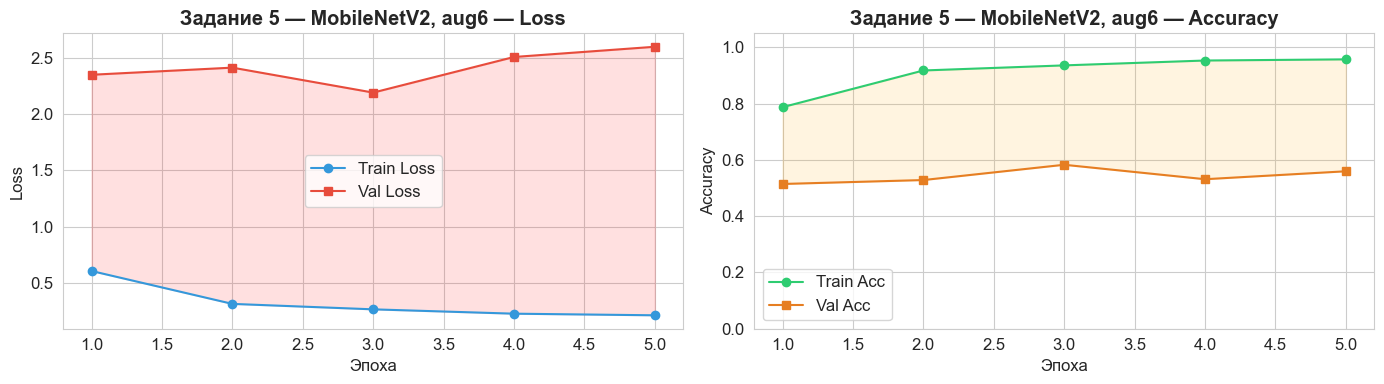

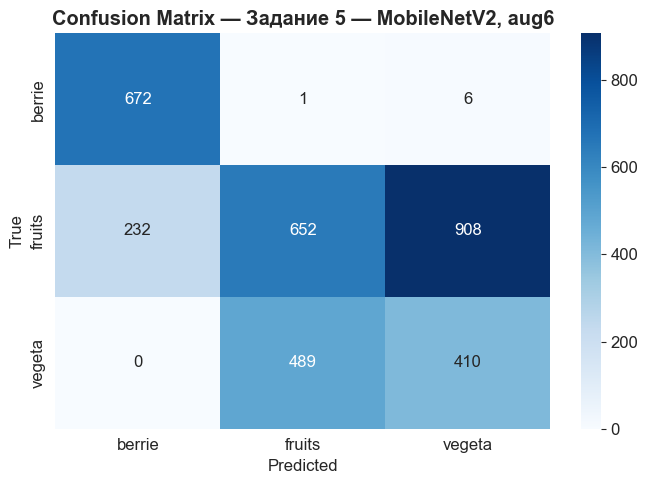

              precision    recall  f1-score   support

      berrie       0.74      0.99      0.85       679
      fruits       0.57      0.36      0.44      1792
      vegeta       0.31      0.46      0.37       899

    accuracy                           0.51      3370
   macro avg       0.54      0.60      0.55      3370
weighted avg       0.54      0.51      0.51      3370

[LOG] Задание 5 — MobileNetV2, aug6
      train=0.9575 | val=0.5828 | test=0.5145
      overfit_gap=+0.3747  ⚠️ переобучение


In [ ]:
# ── Модель 1: MobileNetV2 ─────────────────────────────────────────
base_mobilenet = keras.applications.MobileNetV2(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_mobilenet.trainable = False

model_mobilenet = Sequential([
    base_mobilenet,
    GlobalAveragePooling2D(),
    Dense(512, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(NUM_CLASSES, activation='softmax')
])
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print('MobileNetV2:')
print(f'  Обучаемых параметров: {sum(np.prod(w.shape) for w in model_mobilenet.trainable_weights):,}')
print(f'  Замороженных:         {sum(np.prod(w.shape) for w in model_mobilenet.non_trainable_weights):,}')

train_gen_aug6.reset()
history_mobilenet = model_mobilenet.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)
evaluate_and_log(model_mobilenet, 'Задание 5 — MobileNetV2, aug6', history_mobilenet, val_gen, val_gen)

In [ ]:
# ── Модель 2: EfficientNetB0 ──────────────────────────────────────
base_efficientnet = keras.applications.EfficientNetB0(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_efficientnet.trainable = False

model_efficientnet = Sequential([
    base_efficientnet,
    GlobalAveragePooling2D(),
    Dense(512, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu',
          kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(NUM_CLASSES, activation='softmax')
])
model_efficientnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print('EfficientNetB0:')
print(f'  Обучаемых параметров: {sum(np.prod(w.shape) for w in model_efficientnet.trainable_weights):,}')
print(f'  Замороженных:         {sum(np.prod(w.shape) for w in model_efficientnet.non_trainable_weights):,}')

train_gen_aug6.reset()
history_efficientnet = model_efficientnet.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)
evaluate_and_log(model_efficientnet, 'Задание 5 — EfficientNetB0, aug6', history_efficientnet, val_gen, val_gen)

EfficientNetB0:
  Обучаемых параметров: 789,507
  Замороженных:         4,051,107.0
Epoch 1/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 2436s 3s/step - accuracy: 0.3421 - loss: 1.6732 - val_accuracy: 0.2668 - val_loss: 1.3385 - learning_rate: 1.0000e-04
Epoch 2/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 716s 848ms/step - accuracy: 0.3490 - loss: 1.5169 - val_accuracy: 0.5318 - val_loss: 1.0788 - learning_rate: 1.0000e-04
Epoch 3/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 693s 822ms/step - accuracy: 0.3521 - loss: 1.4356 - val_accuracy: 0.2668 - val_loss: 1.1588 - learning_rate: 1.0000e-04
Epoch 4/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 695s 825ms/step - accuracy: 0.3615 - loss: 1.3653 - val_accuracy: 0.5318 - val_loss: 1.1112 - learning_rate: 1.0000e-04
Epoch 5/20
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 612ms/step - accuracy: 0.3627 - loss: 1.3296
Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 576s 684ms/step - accuracy: 0.3664 - loss: 1.3293 - val_accuracy: 0.2015 - val_loss: 

---
## Итоговое сравнение всех моделей

In [ ]:
# ── Таблица результатов ───────────────────────────────────────────
log_df = pd.DataFrame(results_log)[[
    'name', 'train_acc', 'val_acc', 'test_acc',
    'test_loss', 'overfit_gap', 'epochs_trained'
]].sort_values('test_acc', ascending=False).reset_index(drop=True)

log_df['overfit_gap'] = log_df['overfit_gap'].apply(
    lambda x: f'{x:+.4f} {"⚠️" if x > 0.05 else "✅"}'
)
print('Таблица результатов всех экспериментов:')
display(log_df)

In [ ]:
# ── Сравнительный график всех моделей ────────────────────────────
names = [r['name'].replace('Задание', 'Зад.') for r in results_log]
accs  = [r['test_acc'] for r in results_log]

plt.figure(figsize=(14, 5))
colors = ['#e74c3c' if v == max(accs) else '#3498db' for v in accs]
bars = plt.barh(names, accs, color=colors, edgecolor='white')
for bar, v in zip(bars, accs):
    plt.text(v + 0.003, bar.get_y() + bar.get_height()/2,
             f'{v:.2%}', va='center', fontweight='bold')
plt.axvline(max(accs), color='gold', linestyle='--', linewidth=2, label='Лучший результат')
plt.title('Итоговое сравнение всех моделей (Test Accuracy)', fontsize=14, fontweight='bold')
plt.xlabel('Test Accuracy')
plt.xlim(0, 1.15)
plt.legend()
plt.tight_layout()
plt.show()

best = results_log[accs.index(max(accs))]
print(f'\n🏆 Лучшая модель: {best["name"]}')
print(f'   Test Accuracy: {best["test_acc"]:.2%}')

In [ ]:
# ── Сохранение лучшей модели ──────────────────────────────────────
from keras.models import load_model

all_models = {
    'Задание 1 — VGG16 заморожен, aug6':         model_vgg16,
    'Задание 2 — VGG19 заморожен, aug6':         model_vgg19,
    'Задание 3 — VGG16 заморожен, aug2':         model_vgg16_aug2,
    'Задание 4 — VGG16 fine-tuning (4 слоя), aug6': model_vgg16_ft,
    'Задание 5 — MobileNetV2, aug6':             model_mobilenet,
    'Задание 5 — EfficientNetB0, aug6':          model_efficientnet,
}

best_name  = results_log[accs.index(max(accs))]['name']
best_model = all_models.get(best_name, model_vgg16)

BEST_MODEL_PATH = 'best_model_lab4.keras'
best_model.save(BEST_MODEL_PATH)
print(f'Лучшая модель сохранена: {BEST_MODEL_PATH}')
print(f'Лог-файл: {LOG_FILE}')